# Inleiding

In deze opdracht gaan jullie twee machine learning modellen trainen. Jullie kiezen twee algoritmes uit de lijst hieronder, één om huizenprijzen mee te voorspellen en één voor het diagnosticeren van borstkanker. Jullie leveren dus maar één  Jupyter Notebook in (dus dit bestand) maar met twee aparte gedeeltes: één met de regressie (huizenprijzen zijn een getal) en één met de classificatie methode (wel/geen borstkanker is een categorie). In de volgende opdracht (dus over twee weken), gaan jullie je werk hier verder uitbreiden, dus zorg ervoor dat alles hier op een stevig basisniveau gemaakt is!

Kies een optie per elk van de volgende lijsten:

Keuzes regressiemodellen (huizenprijzen):
1. Gradient Boosting regressie
2. Support vector machines
3. Nearest Neighbour regressie
4. MLP (neural network)
5. Random Forest

Keuzes classificatiemodellen (borstkanker):
1. Naive Bayes
2. Random Forest
3. Gradient boosting classificatie
4. Support Vector Machine
5. Nearest Neighbours classificatie
6. MLP (neural network)

Let op: voor deze opdracht alleen, zoals geschreven in de beoordelingsrubriek voor deze opdracht, komt 25% van jullie cijfers van de kwaliteit van jullie antwoorden tijdens de peer reviews in Feedback Fruits. Deze gaan beoordeeld op individuele basis. Voor de resterende 3 opdrachten worden jullie peer reviews alleen beoordeeld op een ja of nee basis. 

Zoals geschreven in de vakbeschrijving:

"Het niet op tijd of lui maken van een individuele peer review resulteert in een reductie van 0,5 punt voor het cijfer van de bijhorende opdracht van de reviewer."

Gezien dat jullie peer reviews zijn sowieso kwalitatief beoordeeld voor Opdracht 1, is deze halfpunt reductie alleen voor Opdrachten 2 t/m 4 geldig. 

### Algemene Coderen Conventies

De volgorde van het python script is belangrijk. Zo zorg je bijvoorbeeld altijd dat eerst de benodigde packages worden ingeladen geïnstalleerd en geïmporteerd). Verder is het goed om van tevoren jouw working directory te controleren. 

Schrijf het python script daarom met een duidelijke indeling van met verschillende stappen. Bij elke stap dient toelichting worden gegeven:
1. Wat is het doel van deze stap?
2. Wat is de input van deze stap?
3. Wat is de output van deze stap en waar heb je deze output hierna nog nodig?

Hieronder voorbeelden van de verschillende punten hierboven.

In [1]:
### Voorbeeld: Standaard Imports
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split


### Controleer Working Directory
import os
print(os.getcwd())

# Pas je working directory aan indien gewenst
# path = 'C:\\Users\\rburrus\\Desktop\\Jupyter Notebook' # zet hier wat voor jou goed is
# os.chdir(path)
# print(os.getcwd())

df = pd.read_csv('train.csv')
### Voorbeeld: Functie met Beschrijving Schrijven

def voorbeeld_functie(parameter1, parameter2 = 2):
    # Doel: dit functie maakt een bepaalde berekening
    # In: parameter1 (float), parameter2 (integer)
    # Uit: parameter1 macht parameter2 (standaard macht 2)
    
    return parameter1 ** parameter2

c:\Users\Gebruiker\Desktop\data_mining_project_1


# Deelopdracht 1/2 - Regressie Model (Huizenprijzen)

Dit is wat er nodig is voor de hoogste score volgens de beoordelingsrubriek:

"Het gekozen regressie model is correct uitgevoerd in python en is werkend. Daarnaast is er een residuen plot gemaakt. Verder is er uitleg gegeven over de werking van het algoritme. De voor- en nadelen van het algoritme zijn benoemd en een voorbeeld uit de praktijk."

In principe, als je de volgende stappen in deze Jupyter Notebook goed volgen, heb je dit niveau gehaald. Voor bedppalde vragen moet je meer Markdown cellen toevoegen om de ruimte te maken voor een meer uitbreiden antwoord te schrijven.

### Theorievragen

Begin met het beantwoorden van een aantal vragen over het gekozen algoritme (gebruik ook plaatjes bij deze uitleg).

1. Noem een voorbeeld uit de praktijk waarin jullie algoritme wordt gebruikt.

Een bekend voorbeeld uit de praktijk is de geautomatiseerde waardebepaling van woningen (*Automated Valuation Models*, zoals de Zestimate van Zillow). Zulke modellen schatten de waarde van een huis op basis van tientallen kenmerken (vierkante meters, locatie, bouwjaar, staat van onderhoud) en maken veel gebruik van ensembles van beslisbomen, waar Random Forest een bekende vertegenwoordiger van is. Buiten de vastgoedwereld wordt Random Forest ook gebruikt voor onder andere kredietbeoordeling en het herkennen van lichaamsdelen in beeld (Microsoft Kinect).

2. Hoe werkt het algoritme conceptueel? Wat zijn de belangrijkste stappen?

Random Forest is een ensemble methode die bestaat uit meerdere Decision Trees (beslisbomen).

1. Er worden honderden verschillende beslisbomen gemaakt.

2. Elke boom wordt getraind op een willekeurige steekproef (bootstrap) van de data.

3. Bij elke splitsing in de boom wordt alleen naar een willekeurige subset van de features gekeken (dit voorkomt dat alle bomen hetzelfde leren).

4.  Voor regressie neemt het model uiteindelijk het gemiddelde van de voorspellingen van alle bomen. Dit zorgt ervoor dat de fouten van individuele bomen elkaar opheffen (variantiereeductie).

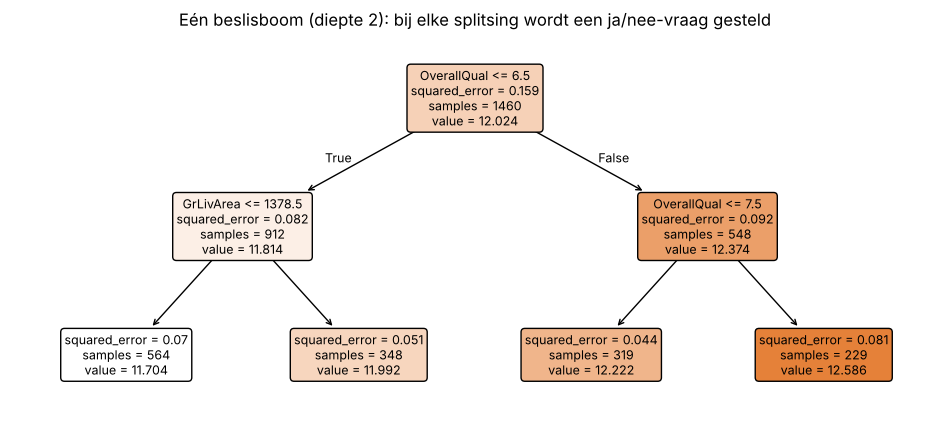

In [2]:
### Doel: Een simpele beslisboom tonen (een Random Forest bestaat uit honderden van zulke bomen)
### In: df (kolommen OverallQual en GrLivArea, en SalePrice)
### Uit: plot van een boom met diepte 2
from sklearn.tree import DecisionTreeRegressor, plot_tree

voorbeeld_X = df[["OverallQual", "GrLivArea"]]
voorbeeld_y = np.log1p(df["SalePrice"])
boom = DecisionTreeRegressor(max_depth=2, random_state=42).fit(voorbeeld_X, voorbeeld_y)

plt.figure(figsize=(12, 5))
plot_tree(boom, feature_names=["OverallQual", "GrLivArea"], filled=True, rounded=True, fontsize=9)
plt.title("Eén beslisboom (diepte 2): bij elke splitsing wordt een ja/nee-vraag gesteld")
plt.show()

*Figuur: een beslisboom stelt achter elkaar ja/nee-vragen over een variabele (bijvoorbeeld "is `OverallQual` ≤ 6,5?"). In elk blad staat de voorspelde (log-)prijs: het gemiddelde van de huizen die in dat blad terechtkomen. Een Random Forest maakt honderden van zulke bomen op verschillende willekeurige steekproeven van de data en neemt het gemiddelde van hun voorspellingen.*

3. Wat zijn de voor- en nadelen van jullie algoritme? In welke situaties werkt het heel goed en wanneer juist niet?

Voordelen:

Het kan complexe, niet-lineaire relaties en interacties tussen variabelen begrijpen (zoals we zagen bij de residuenplot).
Het is erg robuust tegen overfitting.
Het vereist weinig preprocessing (het is bijvoorbeeld niet nodig om data te schalen).
Het geeft inzicht in welke features het belangrijkst zijn.


Nadelen:

Het is een "black box"; je kunt niet makkelijk een simpele formule opstellen zoals bij lineaire regressie.
Traag en geheugenintensief bij extreem grote datasets.
Het kan niet extrapoleren (een huis dat veel duurder is dan ooit in de trainingsdata voorkomt, zal niet goed voorspeld worden).

## Code

Voor het regressie model kunnen jullie deze dataset gebruiken:

https://www.kaggle.com/c/house-prices-advanced-regression-techniques

Gebruik in eerste instantie (deze opdracht) alleen het bestand train.csv. Het doel is om de prijs van huizen (variabele SalePrice) te gaan voorspellen. De input die het model kan gebruiken bestaat uit de overige 80 kolommen.

### Dataverkenning

Wat voor data heb je tot je beschikking? Maak een aantal verkennende analyses om dit te verduidelijken. Welke variabelen bevatten belangrijke informatie en welke niet? Hoe zie je dat?

Dit is wat er nodig is voor de hoogste score volgens de beoordelingsrubriek:

"De data wordt verkend met plots, de kwaliteit wordt bediscussieerd en er zijn acties genomen om fouten te verbeteren. Er wordt onderbouwd welke variabelen belangrijk zijn en er wordt ook naar combinaties/interactie van variabelen gekeken."

Let op: Je kan deze vraag (en soortgelijke vragen hieronder) beantwoorden via zowel aanvullende Markdown cellen (voor tekstuele antwoorden) als Code cellen (voor jouw code zelf, met commentaar erbij). Gebruik gewoon wat je het best helpt om de vraag te beantwoorden. 

In [3]:
### Doel: Data inladen
### In: train.csv
### Uit: DataFrame 'df' met 1460 rijen en 81 kolommen
print("Rows, columns:", df.shape)
print("\nColumn types:")
print(df.dtypes.value_counts())      # how many numeric vs text columns
df.head()

Rows, columns: (1460, 81)

Column types:
str        43
int64      35
float64     3
Name: count, dtype: int64


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,...,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,...,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,...,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,...,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,...,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,...,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


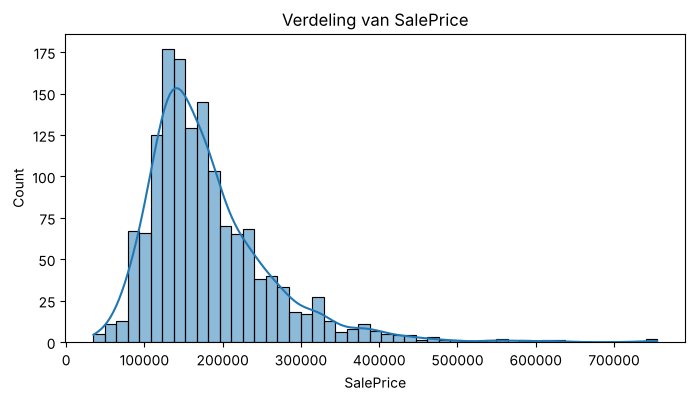

Skewness SalePrice: 1.8828757597682129


In [4]:
### Doel: Eerste verkenning — datatypes, missende waarden, doelvariabele
### In: df
### Uit: Inzicht in kwaliteit van de data

# Target distribution
plt.figure(figsize=(8,4))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Verdeling van SalePrice")
plt.show()

print("Skewness SalePrice:", df["SalePrice"].skew())  # right-skewed → consider log transform



In [5]:
# Missing values overview
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(missing.head(20))
print("\nTotal columns with missing:", len(missing))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

Total columns with missing: 19


**Bevindingen uit de eerste verkenning**

- **SalePrice is rechtsscheef** (skewness ≈ 1.88): een paar zeer dure huizen trekken de staart naar rechts. Daarom voorspellen we `log1p(SalePrice)`; dat maakt de verdeling symmetrischer.
- **Er zijn 19 kolommen met missende waarden**, maar in veel gevallen is een NaN geen echte ontbrekende waarde. Volgens de data-beschrijving betekent NaN bij bijvoorbeeld `PoolQC`, `Alley`, `Fence`, `FireplaceQu` en de `Garage*`/`Bsmt*`-kolommen dat het huis dat element **niet heeft**. Daarom vullen we categorische kolommen met `"None"` (een eigen categorie).
- **`LotFrontage`** mist bij 259 huizen (≈ 18%). Dit is echt ontbrekende informatie; we vullen het aan met de **mediaan** van de kolom, net als de andere numerieke kolommen met missende waarden (o.a. `MasVnrArea`, `GarageYrBlt`).

Aantal uitschieters: 2 | Id's: [524, 1299]


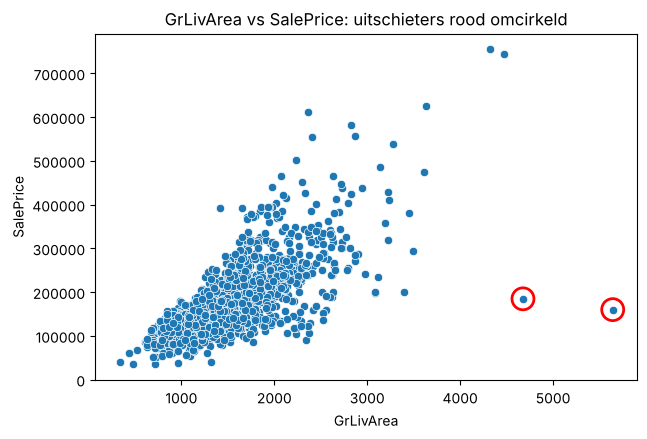

Nieuwe shape van df: (1460, 83)


In [6]:
### Doel: Uitschieters opsporen en twee samengestelde variabelen maken
### In: df
### Uit: scatterplot met uitschieters gemarkeerd; df met extra kolommen TotalSF (totale oppervlakte) en TotalBath (aantal badkamers)
# Uitschieters: zeer grote huizen (> 4000 sq ft) met een opvallend lage prijs
uitschieters = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
print("Aantal uitschieters:", len(uitschieters), "| Id's:", uitschieters["Id"].tolist())

plt.figure(figsize=(7, 4.5))
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"])
plt.scatter(uitschieters["GrLivArea"], uitschieters["SalePrice"], s=250, facecolors="none", edgecolors="red", linewidths=2)
plt.title("GrLivArea vs SalePrice: uitschieters rood omcirkeld"); plt.show()

# Nieuwe variabelen: een koper kijkt naar de totale oppervlakte en het totaal aantal badkamers
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
print("Nieuwe shape van df:", df.shape)

**Uitschieters en nieuwe variabelen.** In de scatterplot staan twee huizen van meer dan 4000 square feet die voor een opvallend lage prijs (< $300.000) zijn verkocht. Dit zijn waarschijnlijk bijzondere verkopen (bijvoorbeeld een onvolledige of niet-marktconforme verkoop). We laten ze in de data staan, omdat een Random Forest weinig last heeft van enkele uitschieters (de bomen splitsen op drempelwaarden) en we de resultaten zo vergelijkbaar houden. Voor het lineaire model zijn ze wel een zwakte, omdat ze de lijn omlaag trekken; het verwijderen van deze twee huizen is een mogelijke verbetering voor de volgende opdracht.

Verder combineren we bestaande kolommen tot `TotalSF` (kelder + 1e + 2e verdieping) en `TotalBath` (halve badkamers tellen voor 0,5), omdat een koper naar het totaal kijkt en niet naar losse delen.

SalePrice       1.000000
OverallQual     0.790982
TotalSF         0.782260
GrLivArea       0.708624
GarageCars      0.640409
TotalBath       0.631731
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Name: SalePrice, dtype: float64


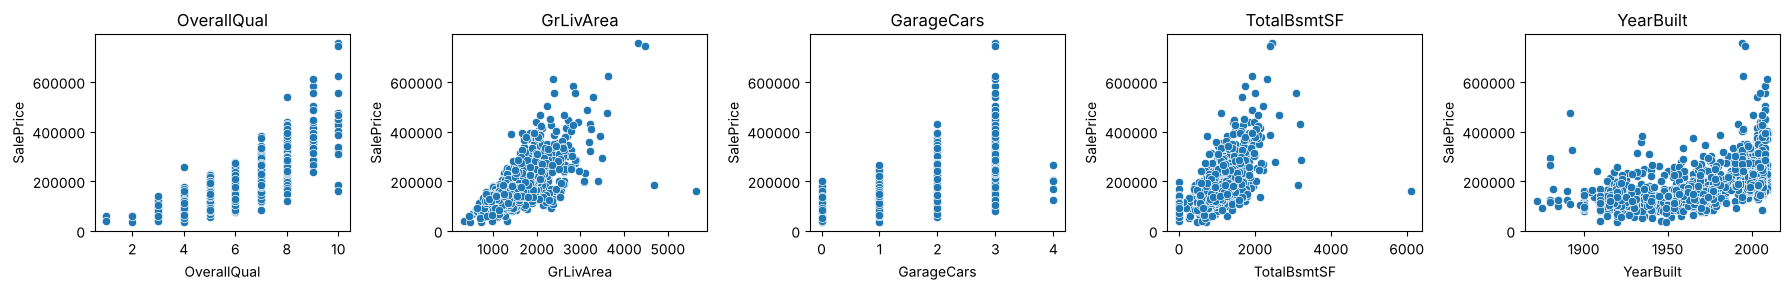

In [7]:
### Doel: Belangrijkste numerieke variabelen vs SalePrice bekijken
### In: df
### Uit: Correlatiematrix + scatterplots

num_cols = df.select_dtypes(include=[np.number]).columns
corr = df[num_cols].corr()["SalePrice"].sort_values(ascending=False)
print(corr.head(15))

top_feats = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "YearBuilt"]
fig, axes = plt.subplots(1, len(top_feats), figsize=(18,3))
for ax, f in zip(axes, top_feats):
    sns.scatterplot(x=df[f], y=df["SalePrice"], ax=ax)
    ax.set_title(f)
plt.tight_layout(); plt.show()

Variabelen met de zwakste samenhang met SalePrice (|r|):
BsmtFinSF2      0.011
BsmtHalfBath    0.017
MiscVal         0.021
Id              0.022
LowQualFinSF    0.026
YrSold          0.029
3SsnPorch       0.045
MoSold          0.046
Name: SalePrice, dtype: float64


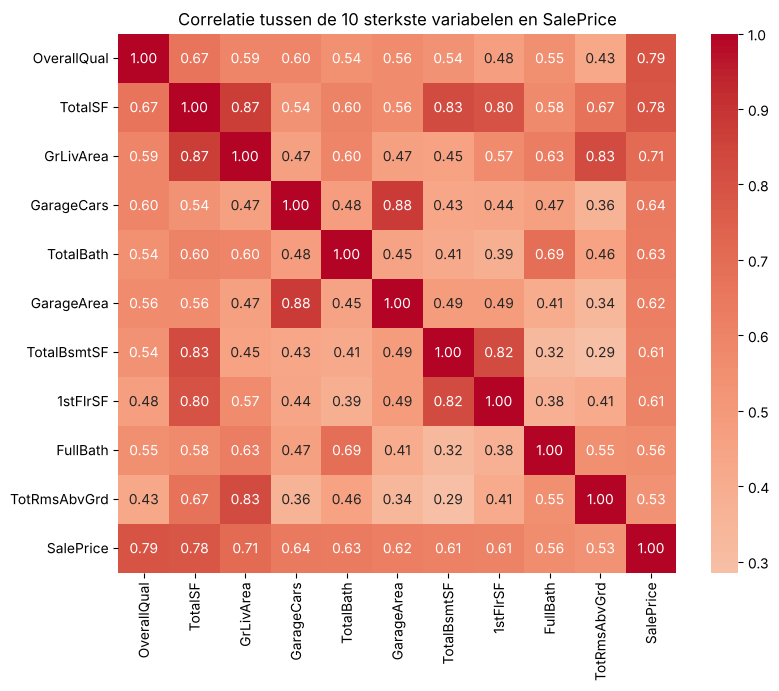

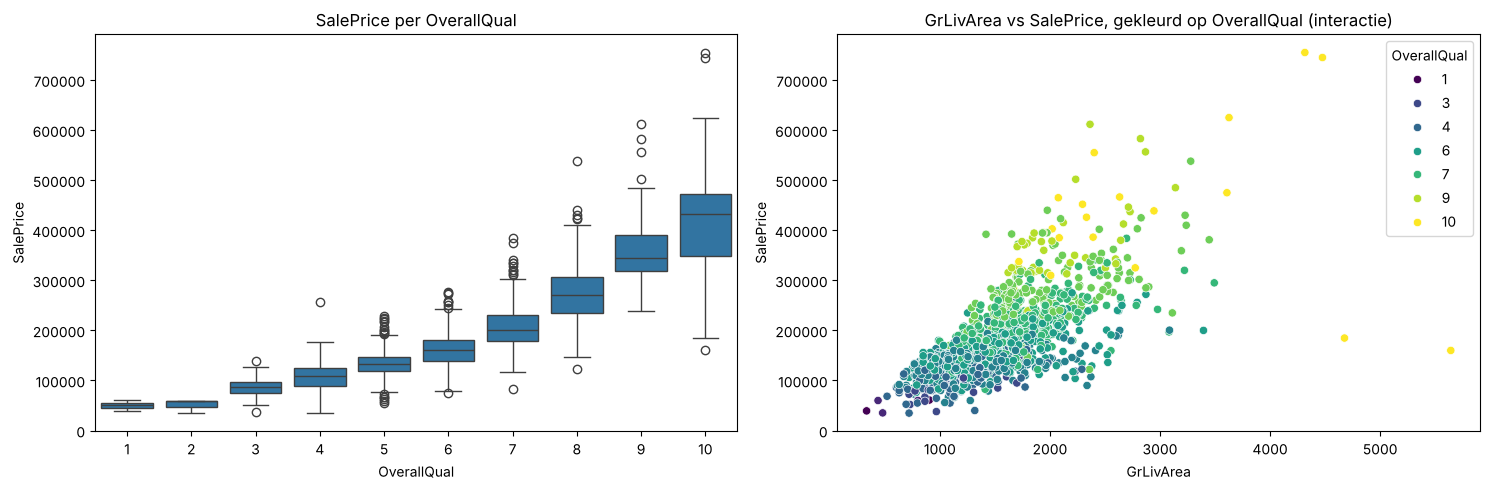

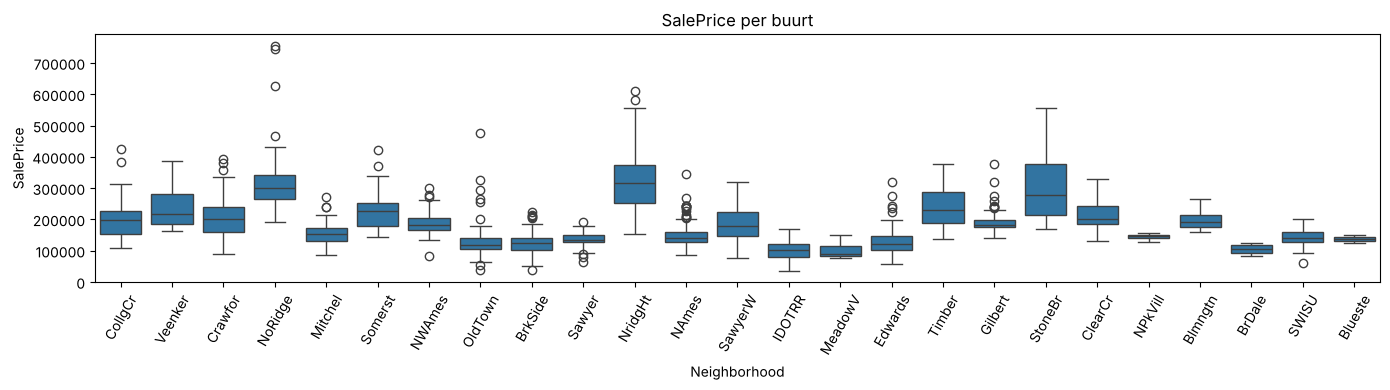

In [8]:
### Doel: Onbelangrijke variabelen, multicollineariteit en interacties tussen variabelen onderzoeken
### In: df
### Uit: lijst zwakste variabelen, heatmap, boxplots en een scatterplot met interactie
num_cols_all = df.select_dtypes(include=[np.number]).columns
corr_all = df[num_cols_all].corr()["SalePrice"].drop("SalePrice")

print("Variabelen met de zwakste samenhang met SalePrice (|r|):")
print(corr_all.abs().sort_values().head(8).round(3))

# Heatmap van de 10 sterkste variabelen: welke variabelen zeggen hetzelfde?
top10 = corr_all.abs().sort_values(ascending=False).head(10).index.tolist()
plt.figure(figsize=(9, 7))
sns.heatmap(df[top10 + ["SalePrice"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlatie tussen de 10 sterkste variabelen en SalePrice")
plt.show()

# Interactie: kwaliteit en oppervlakte samen, en de invloed van de buurt
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(x="OverallQual", y="SalePrice", data=df, ax=axes[0])
axes[0].set_title("SalePrice per OverallQual")
sns.scatterplot(x="GrLivArea", y="SalePrice", hue="OverallQual", palette="viridis", data=df, ax=axes[1])
axes[1].set_title("GrLivArea vs SalePrice, gekleurd op OverallQual (interactie)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(14, 4))
sns.boxplot(x="Neighborhood", y="SalePrice", data=df)
plt.xticks(rotation=60); plt.title("SalePrice per buurt")
plt.tight_layout(); plt.show()

**Welke variabelen zijn belangrijk en welke niet?**

- **Belangrijk:** `OverallQual` (r ≈ 0.79), `TotalSF` (r ≈ 0.78) en `GrLivArea` (r ≈ 0.71) hebben de sterkste samenhang met de prijs. Ook `GarageCars`, `TotalBath` en `YearBuilt` zijn duidelijk gerelateerd.
- **Niet belangrijk:** variabelen zoals `MoSold`, `YrSold`, `MiscVal`, `BsmtFinSF2` en `LowQualFinSF` hebben een correlatie rond 0 (ook het kolomnummer `Id` zegt niets over de prijs, daarom laten we het straks weg). Het verkoopmoment zegt dus bijna niets over de prijs. Een Random Forest negeert zulke variabelen vanzelf grotendeels.
- **Multicollineariteit:** de heatmap laat zien dat sommige variabelen bijna hetzelfde meten, bijvoorbeeld `GarageCars` en `GarageArea`, of `TotalBsmtSF`, `1stFlrSF` en `TotalSF`. Dit is geen probleem voor een Random Forest, maar zou wel problemen geven bij een lineair model met meerdere variabelen.
- **Interacties:** de scatterplot met kleuren laat zien dat de relatie tussen oppervlakte en prijs afhangt van de kwaliteit: bij hoge `OverallQual` groeit de prijs veel sneller met de oppervlakte dan bij lage kwaliteit. Een enkelvoudig lineair model kan zo'n interactie niet vangen, een beslisboom wel. Ook de buurt maakt veel uit (de mediane prijs verschilt sterk per `Neighborhood`).

In [9]:
### Doel: Data opschonen (missende waarden vullen) en omzetten naar numerieke data
### In: df
### Uit: X (features) en y (target)

# 1. Separate features (X) and target (y)
# drop 'Id' omdat het waardeloos is om de prijs te voorspellen, en 'SalePrice' omdat wij dit voorspellen.
y = np.log1p(df["SalePrice"]) 
X = df.drop(columns=["Id", "SalePrice"])

# 2. Fill missing values
num_cols = X.select_dtypes(include=[np.number]).columns
cat_cols = X.select_dtypes(exclude=[np.number]).columns

# Fill numeric missing with median
for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

# Fill categorical missing with "None" 
for col in cat_cols:
    X[col] = X[col].fillna("None")

# 3. One-Hot Encoding (converts text to 1s and 0s)
X_encoded = pd.get_dummies(X, drop_first=True)

print("Original shape:", df.shape)
print("New X shape:", X_encoded.shape) 
print("y shape:", y.shape)

Original shape: (1460, 83)
New X shape: (1460, 262)
y shape: (1460,)


In [10]:
### Doel: Data splitsen in Train en Test sets
### In: X_encoded, y
### Uit: X_train, X_test, y_train, y_test



X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 1168
Testing rows: 292


### Lineaire Regressie model

Maak een enkelvoudig lineaire regressie model (dus met maar één X-variabele, en NIET jouw gekozen regressie model...dit is bedoeld als een soort inleiding) net als de demo in het college.

In [11]:
### Doel: Enkelvoudig lineair regressiemodel trainen
### In: X_train[["GrLivArea"]], y_train
### Uit: Coëfficiënten (m en b)
#  m hoeveel de prijs per extre square foot omhooggaat
# bb the basis prijs als square footage 0 was
from sklearn.linear_model import LinearRegression

# We only grab the "GrLivArea" column
X_train_simple = X_train[["GrLivArea"]]
X_test_simple = X_test[["GrLivArea"]]

lr = LinearRegression()
lr.fit(X_train_simple, y_train)

print("Intercept (b):", lr.intercept_)
print("Coefficient (m):", lr.coef_[0])

Intercept (b): 11.24681560147631
Coefficient (m): 0.0005131870620824862


log(SalePrice) = 11.247 + 0.00051 × GrLivArea

Elke extra square foot woonoppervlak verhoogt de prijs met ongeveer 0.051%.

Wat is de vergelijking die hierbij hoort?

De vergelijking van het enkelvoudige lineaire regressiemodel is:

$$ \log(\text{SalePrice}) = 11.247 + 0.00051 \times \text{GrLivArea} $$

**Interpretatie:**
Omdat we de SalePrice hebben getransformeerd met een logaritme, betekent de coëfficiënt (0.00051) dat elke extra vierkante voet woonoppervlak (GrLivArea) zorgt voor een stijging van ongeveer **0.051%** in de huizenprijs. De intercept (11.247) is de voorspelde log-prijs van een huis met 0 square feet. Dat is geen realistisch huis, dus de intercept heeft hier alleen een wiskundige betekenis.

### Residuen Plot

Maak een residuen plot (de input variabele op de x-as en de fout in de voorspelling op de y-as). Zie voorbeeld hieronder.

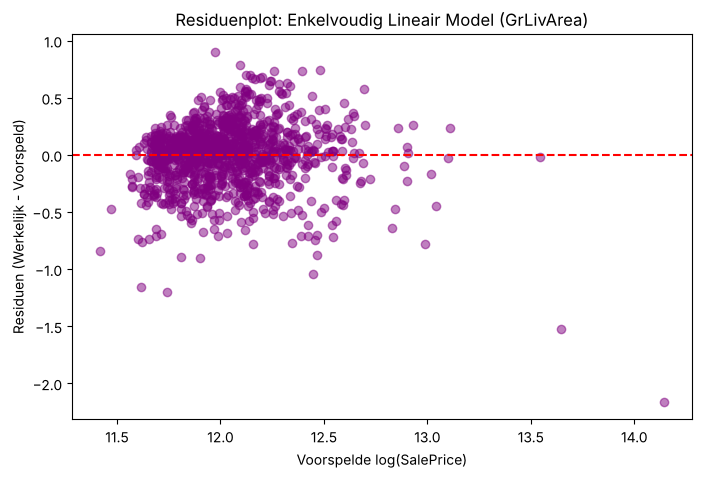

In [12]:
### Doel: Residuenplot voor het enkelvoudige lineaire regressiemodel
### In: lr (LinearRegression model), X_train_simple, y_train
### Uit: Plot van voorspelde waarden vs. fouten

# Voorspellingen en fouten berekenen
preds_simple = lr.predict(X_train_simple)
residuals_simple = y_train - preds_simple

# Plot maken
plt.figure(figsize=(8, 5))
plt.scatter(preds_simple, residuals_simple, alpha=0.5, color='purple')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Voorspelde log(SalePrice)")
plt.ylabel("Residuen (Werkelijk - Voorspeld)")
plt.title("Residuenplot: Enkelvoudig Lineair Model (GrLivArea)")
plt.show()

In [13]:
### Doel: Prestatie van het enkelvoudige lineaire model op de testset (om straks te vergelijken met Random Forest)
### In: lr, X_test_simple, y_test
### Uit: R² en MAE (in dollars) van het lineaire model
from sklearn.metrics import r2_score, mean_absolute_error

pred_lin_test = lr.predict(X_test_simple)
r2_lin = r2_score(y_test, pred_lin_test)
mae_lin = mean_absolute_error(np.expm1(y_test), np.expm1(pred_lin_test))
print(f"Lineair model (alleen GrLivArea) R² op testset: {r2_lin:.4f}")
print(f"Lineair model MAE in dollars: ${mae_lin:,.0f}")

Lineair model (alleen GrLivArea) R² op testset: 0.5402
Lineair model MAE in dollars: $38,255


**Wat zien we in de residuenplot?** Bij een goed model liggen de residuen willekeurig rond 0, zonder patroon. Hier zien we dat niet: de residuen zijn breed uitgespreid en bij een aantal huizen zijn de fouten groot. Het model gebruikt maar één variabele (`GrLivArea`) en kan dus niets met kwaliteit, buurt of bouwjaar. Het verklaart slechts een deel van de variantie (zie R² hierboven). Dat is de reden om over te stappen op een model dat meer variabelen en niet-lineaire verbanden aankan.

In [14]:
### Doel: Random Forest model trainen en evalueren
### In: X_train, y_train, X_test, y_test
### Uit: Model, voorspellingen en foutmetrieken (RMSE, MAE, R²)

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Initialize and train the forest
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# 2.  predictions  test set ( 20% in de vault)
y_pred = rf.predict(X_test)

# 3. bereken de metrics Metrics (log-scale )
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"RMSE (Log Scale): {rmse:.4f}")
print(f"MAE (Log Scale):  {mae:.4f}")
print(f"R² Score:         {r2:.4f}")

# 4. schatting terug naar daadwerkelijke dollars
# (np.expm1 is the reverse of np.log1p)
y_test_dollars = np.expm1(y_test)
y_pred_dollars = np.expm1(y_pred)

rmse_dollars = np.sqrt(mean_squared_error(y_test_dollars, y_pred_dollars))
mae_dollars = mean_absolute_error(y_test_dollars, y_pred_dollars)

print(f"\n--- In Dollars ---")
print(f"RMSE: ${rmse_dollars:,.2f}")
print(f"MAE:  ${mae_dollars:,.2f} (On average, we are off by this much)")

RMSE (Log Scale): 0.1478
MAE (Log Scale):  0.0978
R² Score:         0.8830

--- In Dollars ---
RMSE: $30,327.30
MAE:  $17,449.77 (On average, we are off by this much)


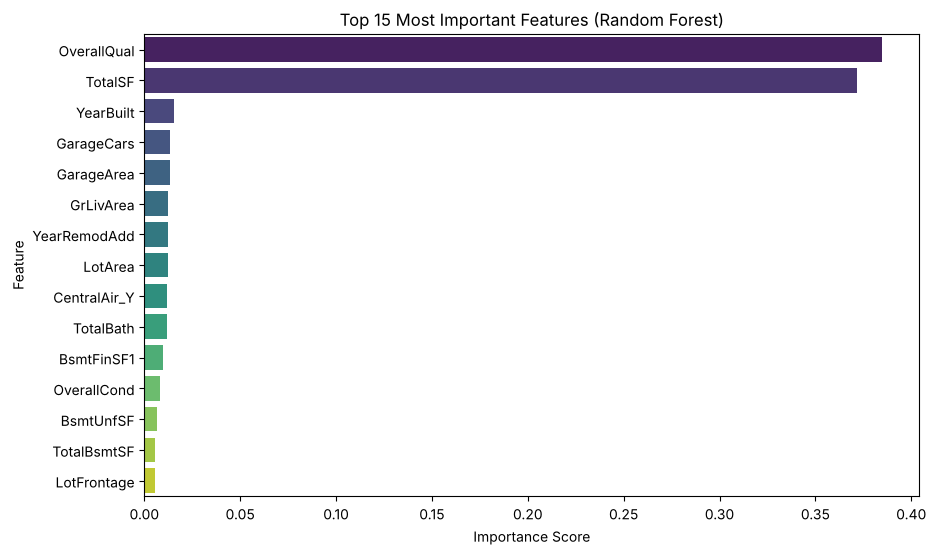

In [15]:
### Doel: Feature importance visualiseren
### In: rf model, X_train
### Uit: Top 15 belangrijkste features plot

importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="viridis", legend=False)
plt.title("Top 15 Most Important Features (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

Wat valt je op?

**Wat valt op:**
1. **Twee variabelen domineren:** `OverallQual` (38%) en `TotalSF` (37%) zijn samen goed voor ongeveer 76% van alle importance. Dat past bij de correlaties uit de verkenning: kwaliteit en totale grootte bepalen het grootste deel van de prijs.
2. **De rest is een lange staart:** de overige variabelen dragen elk slechts ~1% of minder bij. Samen zijn ze wel nuttig (zie de stapsgewijze vergelijking hieronder), maar elke afzonderlijke variabele voegt weinig toe.
3. **Het volledige model presteert goed:** met alle 262 (geëncodeerde) variabelen is de R² op de testset **0.8830** (zie vorige cel). Het model verklaart dus ongeveer 88.3% van de variantie in log(SalePrice).

### Gekozen Regressie Model

Maak nu een voorspelling met jullie gekozen machine learning model en gebruik eerst dezelfde enkele variabele van de enkelvoudig lineaire regressie jullie net hebben gedaan.

In [16]:
### Doel: Random Forest trainen met eerst alleen GrLivArea, daarna met meer variabelen
### In: X_train, y_train
### Uit: Vergelijking van de prestaties (R²)

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Stap 1: Alleen GrLivArea (net als het lineaire model)
X_train_single = X_train[["GrLivArea"]]
X_test_single = X_test[["GrLivArea"]]

rf_single = RandomForestRegressor(n_estimators=100, random_state=42)
rf_single.fit(X_train_single, y_train)
y_pred_single = rf_single.predict(X_test_single)
r2_single = r2_score(y_test, y_pred_single)
print(f"R² met alleen GrLivArea: {r2_single:.4f}")

# Stap 2: Voeg de top 3 belangrijkste variabelen toe

features_4 = ["GrLivArea", "OverallQual", "TotalBsmtSF", "GarageCars"]
X_train_4 = X_train[features_4]
X_test_4 = X_test[features_4]

rf_4 = RandomForestRegressor(n_estimators=100, random_state=42)
rf_4.fit(X_train_4, y_train)
y_pred_4 = rf_4.predict(X_test_4)
r2_4 = r2_score(y_test, y_pred_4)
print(f"R² met 4 variabelen: {r2_4:.4f}")

# Stap 3: Gebruik ALLE variabelen

y_pred_all = rf.predict(X_test)
r2_all = r2_score(y_test, y_pred_all)
print(f"R² met ALLE variabelen: {r2_all:.4f}")

R² met alleen GrLivArea: 0.4552
R² met 4 variabelen: 0.8348
R² met ALLE variabelen: 0.8830


Voeg steeds meer variabelen toe. Laat elke tussenstap zien.

 aantal variabelen     R²  MAE ($)
                 1 0.4552    43932
                 2 0.7505    26483
                 3 0.8240    21543
                 4 0.8348    20135
                 8 0.8654    18324
                20 0.8809    17689
               262 0.8816    17505


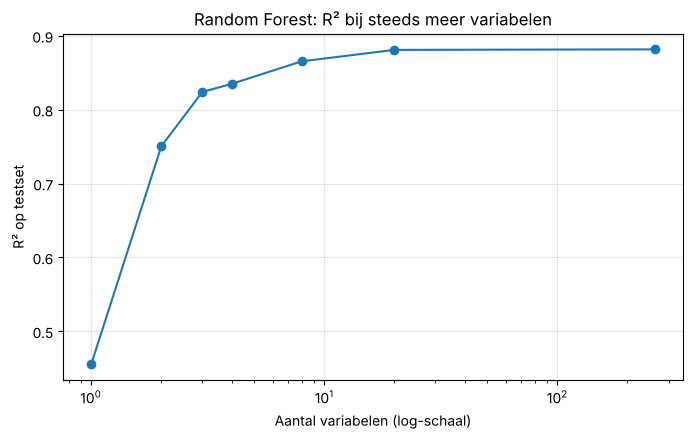

In [17]:
### Doel: Stapsgewijs variabelen toevoegen aan het Random Forest en per stap de prestatie laten zien
### In: X_train, X_test, y_train, y_test, rf (voor de volgorde van belangrijkheid)
### Uit: tabel met R² en MAE per stap + lijnplot (R² tegen aantal variabelen)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# We beginnen met GrLivArea (net als het lineaire model) en voegen steeds belangrijke variabelen toe
stap_1 = ["GrLivArea"]
stap_2 = stap_1 + ["OverallQual"]
stap_3 = stap_2 + ["TotalBsmtSF"]
stap_4 = stap_3 + ["GarageCars"]
stap_8 = stap_4 + ["YearBuilt", "TotalBath", "LotArea", "YearRemodAdd"]
importances_all = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
stap_20 = importances_all.head(20).index.tolist()          # de 20 belangrijkste volgens het volledige model
stap_alle = X_train.columns.tolist()                        # alle variabelen

rijen = []
for feats in [stap_1, stap_2, stap_3, stap_4, stap_8, stap_20, stap_alle]:
    m = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    m.fit(X_train[feats], y_train)
    p = m.predict(X_test[feats])
    rijen.append({"aantal variabelen": len(feats),
                  "R²": round(r2_score(y_test, p), 4),
                  "MAE ($)": round(mean_absolute_error(np.expm1(y_test), np.expm1(p)))})
stap_tabel = pd.DataFrame(rijen)
print(stap_tabel.to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(stap_tabel["aantal variabelen"], stap_tabel["R²"], marker="o")
plt.xscale("log"); plt.xlabel("Aantal variabelen (log-schaal)"); plt.ylabel("R² op testset")
plt.title("Random Forest: R² bij steeds meer variabelen"); plt.grid(alpha=0.3); plt.show()

**Wat zien we bij het toevoegen van variabelen?** De grootste sprong zit in de eerste stappen: van alleen `GrLivArea` naar `GrLivArea` + `OverallQual` stijgt de R² van **0.455** naar **0.750**. Daarna wordt de winst per extra variabele snel kleiner en vanaf ongeveer 15 à 20 variabelen vlakt de lijn af. Dit is een typisch geval van afnemende meeropbrengst.

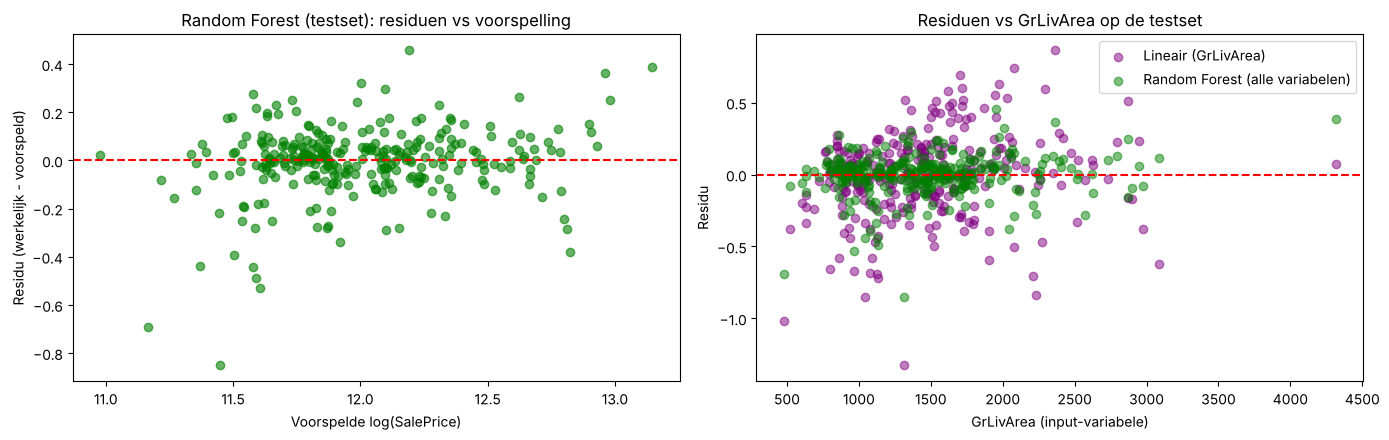

Standaarddeviatie residuen lineair:       0.2934
Standaarddeviatie residuen Random Forest: 0.1479


In [18]:
### Doel: Residuenplot voor het Random Forest model, vergeleken met het enkelvoudige lineaire model
### In: rf, lr, X_test, X_test_simple, y_test
### Uit: twee plots: residuen tegen voorspelling en residuen tegen de input-variabele GrLivArea
pred_rf_test = rf.predict(X_test)
res_rf = y_test - pred_rf_test
res_lin = y_test - lr.predict(X_test_simple)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(pred_rf_test, res_rf, alpha=0.6, color="green")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Voorspelde log(SalePrice)"); axes[0].set_ylabel("Residu (werkelijk - voorspeld)")
axes[0].set_title("Random Forest (testset): residuen vs voorspelling")

axes[1].scatter(X_test["GrLivArea"], res_lin, alpha=0.5, color="purple", label="Lineair (GrLivArea)")
axes[1].scatter(X_test["GrLivArea"], res_rf, alpha=0.5, color="green", label="Random Forest (alle variabelen)")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("GrLivArea (input-variabele)"); axes[1].set_ylabel("Residu")
axes[1].set_title("Residuen vs GrLivArea op de testset"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Standaarddeviatie residuen lineair:       {res_lin.std():.4f}")
print(f"Standaarddeviatie residuen Random Forest: {res_rf.std():.4f}")

**Residuen Random Forest:** de residuen liggen nu veel dichter bij 0 dan bij het lineaire model (kleinere standaarddeviatie, zie hierboven) en er is geen duidelijk patroon meer in de plot. De grootste fouten zitten aan de randen van het prijsbereik: een paar zeer goedkope huizen worden overschat (negatieve residuen) en de duurste huizen worden onderschat (positieve residuen). Dat is typisch voor een Random Forest: voorspellingen worden naar het gemiddelde getrokken en het model kan niet buiten de prijzen uit de trainingsdata extrapoleren.

Wanneer ben je klaar?

**Conclusie van het Regressiemodel:**

We zijn klaar met het regressiemodel. De stappen die we hebben doorlopen:

- Een enkelvoudig lineair model met alleen `GrLivArea` haalt een R² van **0.540** op de testset. De residuenplot laat zien dat de fouten niet willekeurig zijn: dit model kan de complexe huizenmarkt niet goed beschrijven.
- Een Random Forest met alleen `GrLivArea` komt op **0.455**. Met twee variabelen (`+ OverallQual`) stijgt dit naar **0.750** en met vier variabelen naar **0.835**.
- Met alle 262 variabelen halen we een **R² van 0.8830**, RMSE (log) 0.1478 en een gemiddelde fout (MAE) van ongeveer **$17.450** per huis. Voorbij ±20 variabelen is de winst vrijwel nul (afnemende meeropbrengst), dus we gebruiken het volledige model; de Random Forest heeft weinig last van overbodige variabelen.
- De residuenplot van het Random Forest laat zien dat de fouten rond 0 liggen en veel kleiner zijn dan bij het lineaire model. De grootste fouten zitten aan de randen (goedkoopste huizen worden overschat, duurste onderschat), wat past bij het nadeel dat een Random Forest slecht extrapoleert.

Hiermee is het regressiegedeelte succesvol afgerond. In de volgende opdracht kunnen we met hyperparameter tuning (`max_depth`, `max_features`, `n_estimators`) en cross-validatie proberen de fout nog verder te verlagen.

# Deelopdracht 2/2 - Classificatie Model (Borstkanker)

Dit is wat er nodig is voor de hoogste score volgens de beoordelingsrubriek:

"Het gekozen classificatie model is correct uitgevoerd in python en is werkend. Daarnaast is er uitleg gegeven over de werking van het algoritme. De voor- en nadelen van het algoritme zijn benoemd en een voorbeeld uit de praktijk."

In principe, als je de volgende stappen in deze Jupyter Notebook goed volgen, heb je dit niveau gehaald. Voor bedppalde vragen moet je meer Markdown cellen toevoegen om de ruimte te maken voor een meer uitbreiden antwoord te schrijven.

### Theorievragen

Begin met het beantwoorden van een aantal vragen over het gekozen algoritme (gebruik ook plaatjes bij deze uitleg).

1. Noem een voorbeeld uit de praktijk waarin jullie algoritme wordt gebruikt.

Voor de classificatie kiezen we de **Support Vector Machine (SVM)** (optie 4), dus een ander algoritme dan bij de regressie.

**Voorbeelden uit de praktijk:** SVM's worden veel gebruikt voor tekstclassificatie (bijvoorbeeld spamfilters en het indelen van nieuwsartikelen), handschriftherkenning (cijfers en letters) en in de biomedische wereld, bijvoorbeeld om tumoren te classificeren op basis van genexpressiedata of medische beelden. Onze dataset (borstkanker op basis van celkernmetingen) is precies zo'n toepassing: een SVM is goed in het scheiden van twee klassen op basis van veel numerieke metingen.

2. Hoe werkt het algoritme conceptueel? Wat zijn de belangrijkste stappen?

**Conceptuele werking van een SVM:**

1. **Twee klassen scheiden met een grens.** De SVM zoekt de beste scheidingslijn (in 2D) of *hypervlak* (in meer dimensies) tussen de klassen, hier goedaardig (B) en kwaadaardig (M).
2. **Maximale marge.** Van alle mogelijke lijnen kiest de SVM de lijn met de grootste afstand (*marge*) tot de dichtstbijzijnde punten van beide klassen. Een brede marge geeft meestal een betere generalisatie naar nieuwe data.
3. **Support vectors.** Alleen de punten die op of binnen de marge liggen (de *support vectors*) bepalen de grens. Alle andere punten kunnen worden weggelaten zonder dat het model verandert.
4. **Soft margin (parameter C).** Echte data is zelden perfect scheidbaar. Met parameter `C` bepaal je hoeveel fouten binnen de marge worden toegestaan: een kleine `C` geeft een bredere marge met meer fouten (minder overfitting), een grote `C` straft fouten zwaarder (kans op overfitting).
5. **Kernel trick.** Als de klassen niet met een rechte lijn te scheiden zijn, projecteert de SVM de data impliciet naar een hogere dimensie waar dat wel kan. Met de veelgebruikte **RBF-kernel** (parameter `gamma`) krijg je zo een flexibele, gebogen grens.
6. **Schalen is noodzakelijk.** Omdat de SVM met afstanden werkt, moeten alle variabelen op dezelfde schaal staan (bijv. `StandardScaler`). Anders domineert een variabele met grote getallen (zoals `area_mean`) de rest.

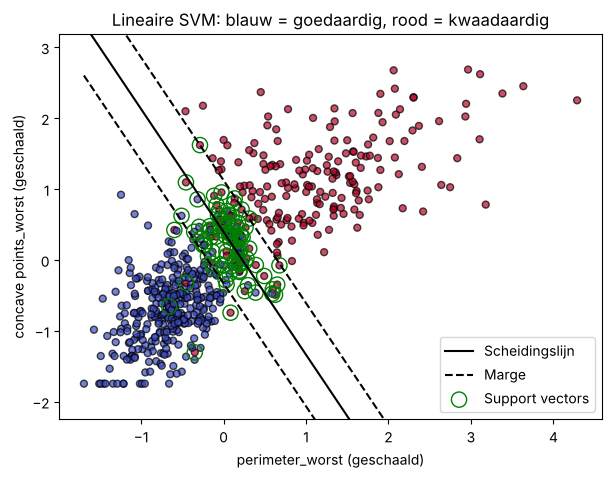

In [19]:
### Doel: De werking van een SVM visualiseren met twee variabelen (grens, marge en support vectors)
### In: data.csv (alleen perimeter_worst en concave points_worst, geschaald)
### Uit: scatterplot met de scheidingslijn van een lineaire SVM
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

plaatje = pd.read_csv("data.csv")
twee = StandardScaler().fit_transform(plaatje[["perimeter_worst", "concave points_worst"]])
kleur = (plaatje["diagnosis"] == "M").astype(int)

svm_demo = SVC(kernel="linear", C=1).fit(twee, kleur)
w = svm_demo.coef_[0]; b = svm_demo.intercept_[0]
x_lijn = np.linspace(twee[:, 0].min(), twee[:, 0].max(), 100)
y_midden = -(w[0] * x_lijn + b) / w[1]            # de scheidingslijn: w0*x + w1*y + b = 0
y_marge = 1 / w[1]                                # afstand (verticaal) tot de marge-lijnen

plt.figure(figsize=(7, 5))
plt.scatter(twee[:, 0], twee[:, 1], c=kleur, cmap="coolwarm", edgecolor="k", s=25, alpha=0.7)
plt.plot(x_lijn, y_midden, "k-", label="Scheidingslijn")
plt.plot(x_lijn, y_midden + y_marge, "k--", label="Marge")
plt.plot(x_lijn, y_midden - y_marge, "k--")
plt.scatter(svm_demo.support_vectors_[:, 0], svm_demo.support_vectors_[:, 1], s=120, facecolors="none", edgecolors="green", label="Support vectors")
plt.ylim(twee[:, 1].min() - 0.5, twee[:, 1].max() + 0.5)
plt.xlabel("perimeter_worst (geschaald)"); plt.ylabel("concave points_worst (geschaald)")
plt.title("Lineaire SVM: blauw = goedaardig, rood = kwaadaardig"); plt.legend(); plt.show()

3. Wat zijn de voor- en nadelen van jullie algoritme? In welke situaties werkt het heel goed en wanneer juist niet?

**Voordelen:**
- Werkt goed bij data met veel variabelen (hoge dimensie), ook als er relatief weinig voorbeelden zijn, zoals bij deze dataset (30 variabelen, 569 patiënten).
- Door de marge-maximalisatie en de `C`-parameter is het model goed te regelen tegen overfitting.
- Met de kernel trick kan het ook gebogen, niet-lineaire grenzen leren.
- Geheugenefficiënt: alleen de support vectors bepalen het model.

**Nadelen:**
- **Variabelen moeten geschaald worden**, anders werkt het model slecht.
- Trainen wordt traag bij heel grote datasets (rekentijd groeit ruwweg kwadratisch tot kubisch met het aantal voorbeelden).
- Het is een "black box": het is lastig uit te leggen *waarom* een patiënt als kwaadaardig wordt geclassificeerd, wat in de medische praktijk een bezwaar is.
- Geeft standaard geen kansen maar alleen een klasse, en is gevoelig voor de keuze van `C`, `gamma` en de kernel (hyperparameter tuning is nodig).
- Gevoelig voor ruis en overlappende klassen.

**Wanneer goed / minder goed:** goed bij middelgrote datasets met numerieke, geschaalde variabelen en een duidelijke scheiding tussen klassen (zoals hier). Minder geschikt bij zeer grote datasets, veel categorische variabelen of als uitlegbaarheid belangrijk is.

## Code

Voor de classificatie opdracht maken jullie gebruik van de volgende dataset:

https://www.kaggle.com/uciml/breast-cancer-wisconsin-data

Jullie gaan voorspellen wie wel en wie geen diagnose borstkanker krijgt op basis van een aantal kolommen met beschikbare informatie.

### Dataverkenning

Wat voor data heb je tot je beschikking? Maak een aantal verkennende analyses om dit te verduidelijken. Welke variabelen bevatten belangrijke informatie en welke niet? Hoe zie je dat?

Dit is wat er nodig is voor de hoogste score volgens de beoordelingsrubriek:

"De data wordt verkend met plots, de kwaliteit wordt bediscussieerd en er zijn acties genomen om fouten te verbeteren. Er wordt onderbouwd welke variabelen belangrijk zijn en er wordt ook naar combinaties/interactie van variabelen gekeken."

In [20]:
### Doel: Data inladen en eerste inspectie van de borstkanker-dataset
### In: data.csv
### Uit: DataFrame 'bc' met 569 rijen; inzicht in datatypes, missende waarden en dubbele rijen
bc = pd.read_csv("data.csv")
print("Rows, columns:", bc.shape)
print("\nColumn types:")
print(bc.dtypes.value_counts())

missend = bc.isnull().sum()
print("\nKolommen met missende waarden:")
print(missend[missend > 0])
print("\nDubbele rijen:", bc.duplicated().sum(), "| dubbele id's:", bc["id"].duplicated().sum())
bc.head()

Rows, columns: (569, 33)

Column types:
float64    31
int64       1
str         1
Name: count, dtype: int64

Kolommen met missende waarden:
Unnamed: 32    569
dtype: int64

Dubbele rijen: 0 | dubbele id's: 0


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Shape na opschonen: (569, 32)
Missende waarden over 32 kolommen: 0

Klassenverdeling:
diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.7 %
M    37.3 %
Name: count, dtype: str


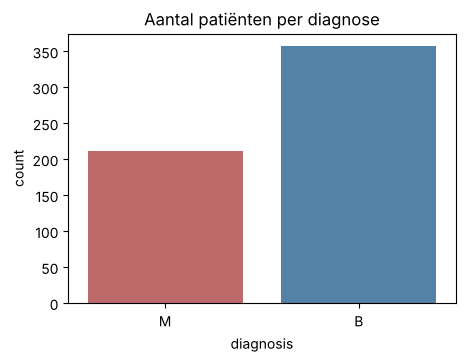

,mean,std,min,max
radius_mean,14.127,3.524,6.981,28.110
texture_mean,19.290,4.301,9.710,39.280
perimeter_mean,91.969,24.299,43.790,188.500
area_mean,654.889,351.914,143.500,2501.000
smoothness_mean,0.096,0.014,0.053,0.163
compactness_mean,0.104,0.053,0.019,0.345
concavity_mean,0.089,0.080,0.000,0.427
concave points_mean,0.049,0.039,0.000,0.201
symmetry_mean,0.181,0.027,0.106,0.304
fractal_dimension_mean,0.063,0.007,0.050,0.097


In [21]:
### Doel: Data opschonen en de doelvariabele omzetten naar getallen
### In: bc
### Uit: bc zonder 'id' en 'Unnamed: 32'; nieuwe kolom 'target' (1 = kwaadaardig (M), 0 = goedaardig (B))
# 'Unnamed: 32' is een lege kolom (alleen NaN, waarschijnlijk een extra komma in het csv-bestand) en 'id' is alleen een patiëntnummer
bc = bc.drop(columns=["Unnamed: 32", "id"])
bc["target"] = (bc["diagnosis"] == "M").astype(int)

print("Shape na opschonen:", bc.shape)
print("Missende waarden over", bc.shape[1], "kolommen:", bc.isnull().sum().sum())

# Klassenverdeling: is de data in balans?
aantal = bc["diagnosis"].value_counts()
print("\nKlassenverdeling:")
print(aantal)
print((aantal / len(bc) * 100).round(1).astype(str) + " %")
plt.figure(figsize=(5, 3.5))
sns.countplot(x="diagnosis", data=bc, hue="diagnosis", palette={"B": "steelblue", "M": "indianred"}, legend=False)
plt.title("Aantal patiënten per diagnose"); plt.show()
bc.describe().T[["mean", "std", "min", "max"]].round(3).head(12)

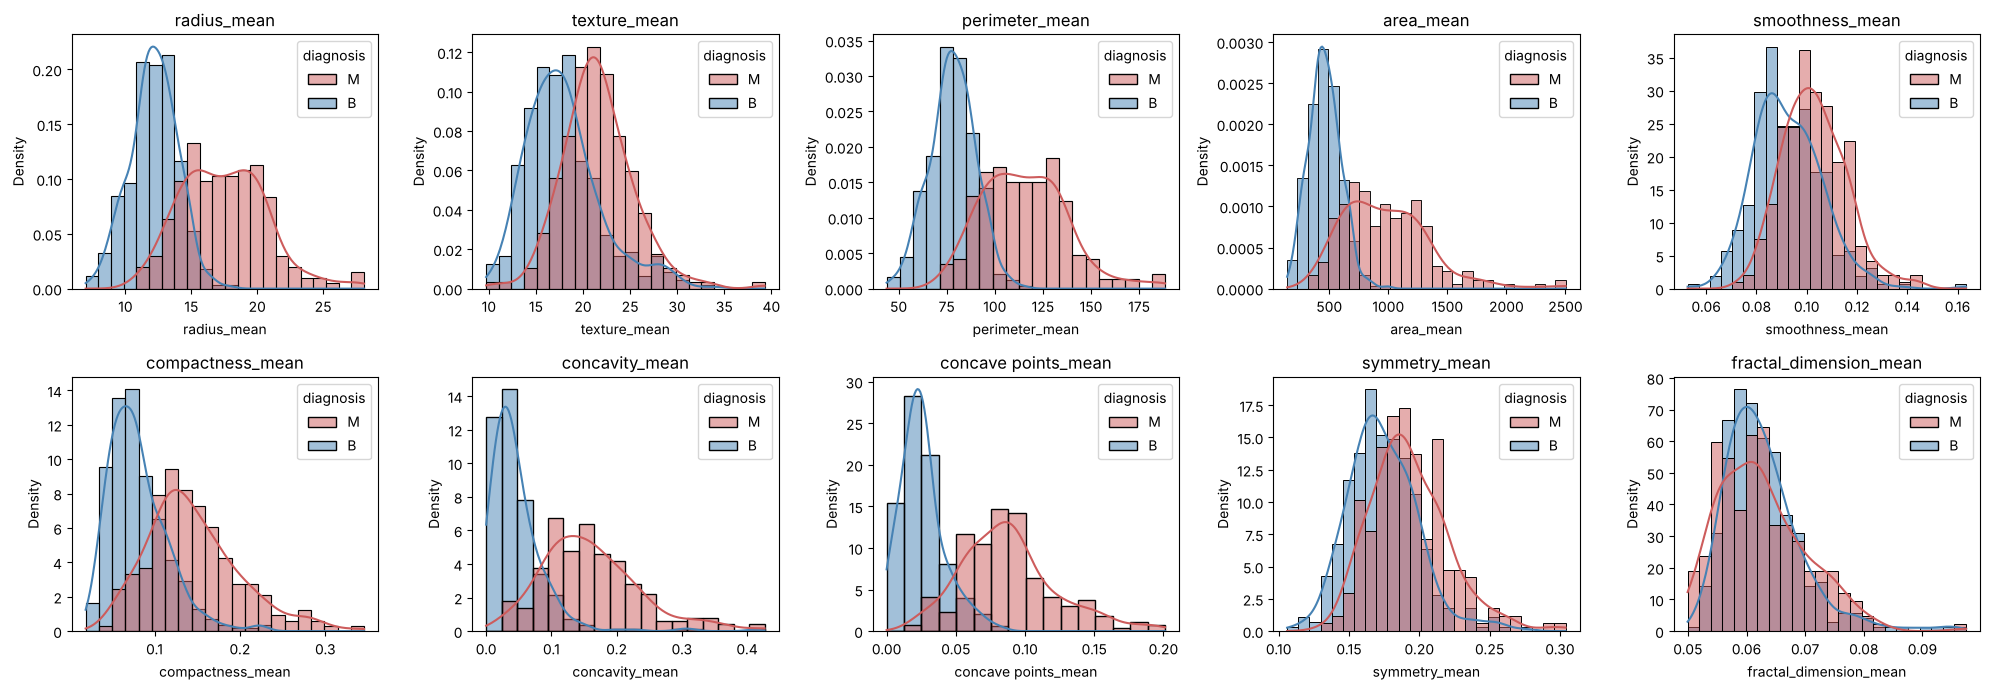

In [22]:
### Doel: Bekijken welke variabelen goedaardige en kwaadaardige tumoren van elkaar onderscheiden
### In: bc
### Uit: histogrammen van de 10 '_mean'-variabelen per diagnose
mean_cols = [c for c in bc.columns if c.endswith("_mean")]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), mean_cols):
    sns.histplot(data=bc, x=col, hue="diagnosis", palette={"B": "steelblue", "M": "indianred"}, kde=True, stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

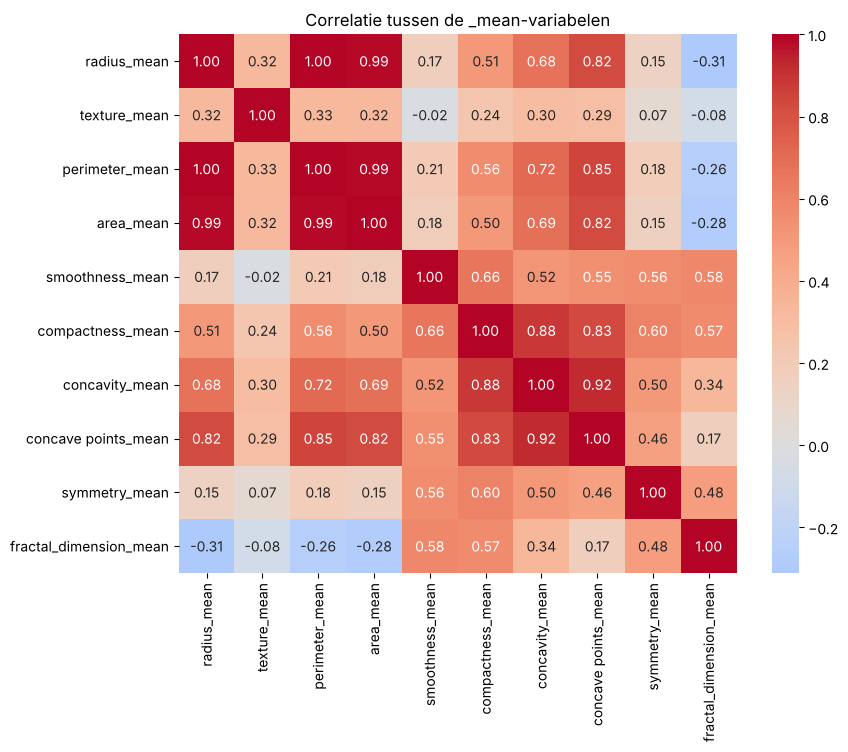

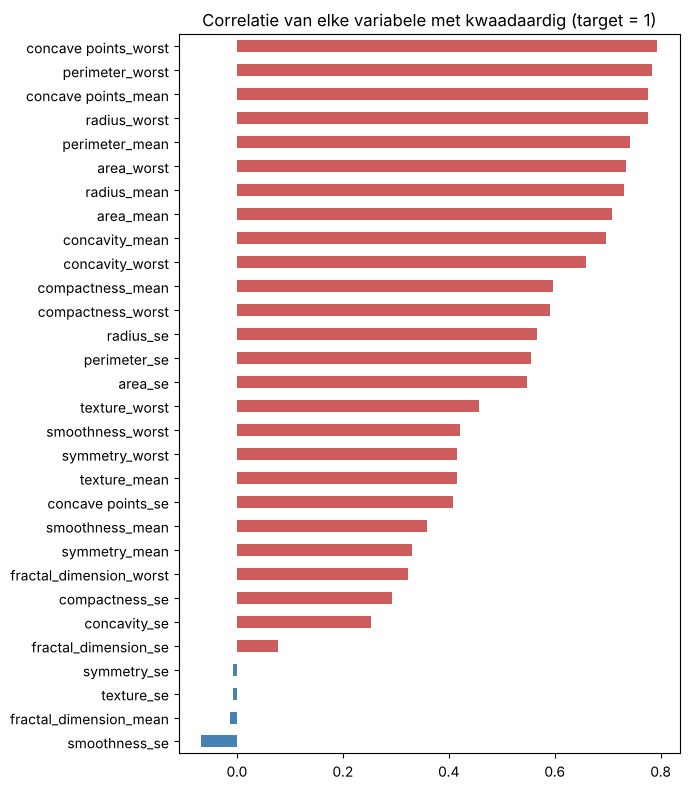

Sterkste 5:
concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
Name: target, dtype: float64

Zwakste 5:
symmetry_se               0.007
texture_se                0.008
fractal_dimension_mean    0.013
smoothness_se             0.067
fractal_dimension_se      0.078
Name: target, dtype: float64


In [23]:
### Doel: Samenhang tussen variabelen onderling (multicollineariteit) en met de diagnose onderzoeken
### In: bc
### Uit: heatmap van de _mean-variabelen en staafdiagram van de correlatie met 'target'
feature_cols = [c for c in bc.columns if c not in ("diagnosis", "target")]

plt.figure(figsize=(9, 7))
sns.heatmap(bc[mean_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlatie tussen de _mean-variabelen"); plt.show()

corr_target = bc[feature_cols + ["target"]].corr()["target"].drop("target").sort_values()
plt.figure(figsize=(7, 8))
corr_target.plot(kind="barh", color=np.where(corr_target > 0, "indianred", "steelblue"))
plt.title("Correlatie van elke variabele met kwaadaardig (target = 1)"); plt.tight_layout(); plt.show()

print("Sterkste 5:"); print(corr_target.abs().sort_values(ascending=False).head(5).round(3))
print("\nZwakste 5:"); print(corr_target.abs().sort_values().head(5).round(3))

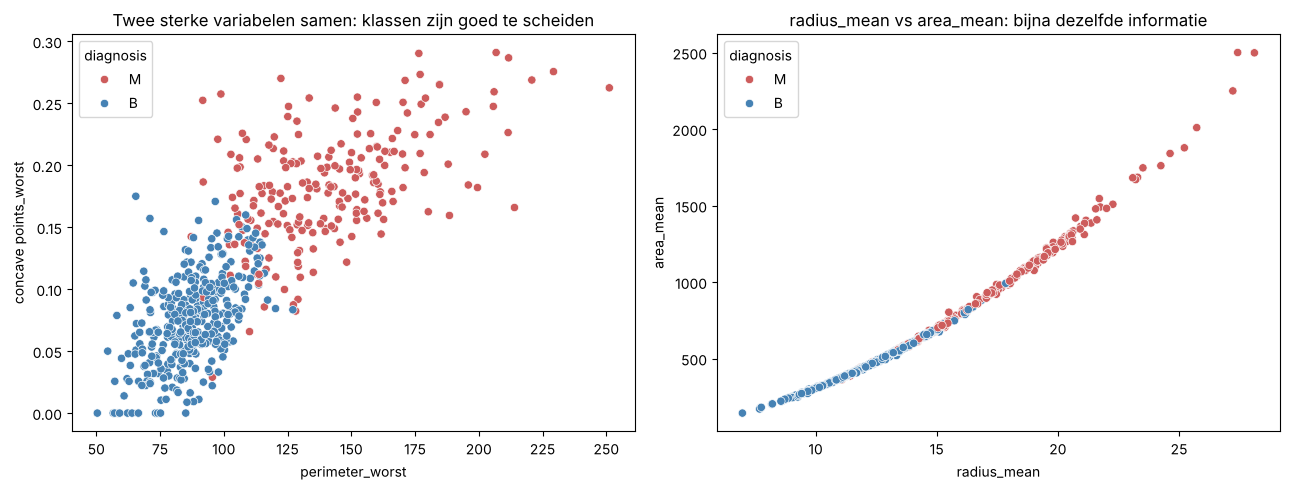

Correlatie radius_mean - perimeter_mean: 0.998
Correlatie radius_mean - area_mean:       0.987


In [24]:
### Doel: Combinaties van variabelen bekijken (interactie) en redundante variabelen laten zien
### In: bc
### Uit: twee scatterplots: twee sterke voorspellers samen, en twee bijna identieke variabelen
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=bc, x="perimeter_worst", y="concave points_worst", hue="diagnosis", palette={"B": "steelblue", "M": "indianred"}, ax=axes[0])
axes[0].set_title("Twee sterke variabelen samen: klassen zijn goed te scheiden")
sns.scatterplot(data=bc, x="radius_mean", y="area_mean", hue="diagnosis", palette={"B": "steelblue", "M": "indianred"}, ax=axes[1])
axes[1].set_title("radius_mean vs area_mean: bijna dezelfde informatie")
plt.tight_layout(); plt.show()
print("Correlatie radius_mean - perimeter_mean:", round(bc["radius_mean"].corr(bc["perimeter_mean"]), 3))
print("Correlatie radius_mean - area_mean:      ", round(bc["radius_mean"].corr(bc["area_mean"]), 3))

**Wat voor data hebben we?** De dataset bevat 569 patiënten met per patiënt 30 numerieke metingen van celkernen uit een fijne-naaldbiopsie. Het zijn 10 eigenschappen (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry en fractal dimension), elk als gemiddelde (`_mean`), standaardfout (`_se`) en slechtste/grootste waarde (`_worst`). De doelvariabele `diagnosis` is B (goedaardig, 357) of M (kwaadaardig, 212).

**Kwaliteit en acties:**
- De kolom `Unnamed: 32` is volledig leeg en `id` is alleen een patiëntnummer; beide zijn verwijderd. Verder zijn er geen missende waarden en geen dubbele rijen.
- De klassen zijn redelijk in balans (ongeveer 62.7% goedaardig en 37.3% kwaadaardig). Een model dat altijd "goedaardig" voorspelt zou dus al **62.7%** correct zijn; dit is de ondergrens waar we elk model mee moeten vergelijken.
- De variabelen hebben zeer verschillende schalen (`area_mean` loopt in de honderden/duizenden, `smoothness_mean` rond 0,1), dus voor een SVM is schalen verplicht.

**Welke variabelen zijn belangrijk en welke niet?**
- **Belangrijk:** de `_worst`- en `_mean`-variabelen van grootte en vorm: `concave points_worst`, `perimeter_worst`, `concave points_mean`, `radius_worst`, `perimeter_mean` en `area_worst` hebben de sterkste samenhang met de diagnose. In de histogrammen is te zien dat kwaadaardige tumoren duidelijk grotere en onregelmatigere celkernen hebben.
- **Minder belangrijk:** variabelen als `fractal_dimension_mean`, `texture_se`, `symmetry_se` en `smoothness_se` onderscheiden de twee klassen nauwelijks (de verdelingen overlappen bijna volledig).
- **Multicollineariteit:** `radius`, `perimeter` en `area` zijn bijna perfect gecorreleerd (r ≈ 0,998 voor `radius_mean` en `perimeter_mean`), omdat ze meetkundig aan elkaar gerelateerd zijn. Dit betekent dat het toevoegen van de tweede of derde variabele uit zo'n groep weinig nieuwe informatie geeft.
- **Interactie:** in de scatterplot van `perimeter_worst` en `concave points_worst` zijn de twee klassen met twee variabelen samen al goed te scheiden, beter dan met elk afzonderlijk. Dat is precies wat we hieronder gaan testen door variabelen stap voor stap toe te voegen.

### Gekozen Classificaite Model

Pas het gekozen machine learning algoritme toe met maar één variabele.

In [25]:
### Doel: Data splitsen, schalen en een hulpfunctie maken om de SVM te trainen en te evalueren
### In: bc
### Uit: Xb_train_s, Xb_test_s (geschaald), yb_train, yb_test en de functie evalueer_svm()
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# stratify=y zorgt dat de verhouding goedaardig/kwaadaardig in train en test gelijk blijft
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    bc[feature_cols], bc["target"], test_size=0.2, random_state=42, stratify=bc["target"]
)
print("Training rows:", Xb_train.shape[0], "| Testing rows:", Xb_test.shape[0])

# Een SVM werkt met afstanden, dus alle variabelen moeten op dezelfde schaal staan.
# We bepalen de schaal (gemiddelde en spreiding) alleen op de trainingsdata en passen die toe op de testdata.
scaler = StandardScaler()
Xb_train_s = pd.DataFrame(scaler.fit_transform(Xb_train), columns=Xb_train.columns, index=Xb_train.index)
Xb_test_s = pd.DataFrame(scaler.transform(Xb_test), columns=Xb_test.columns, index=Xb_test.index)

def evalueer_svm(features):
    # Doel: SVM trainen op de gekozen variabelen en de nauwkeurigheid op de testset meten
    # In: features (lijst met kolomnamen)
    # Uit: (accuracy op de testset, getraind model)
    model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
    model.fit(Xb_train_s[features], yb_train)
    acc = accuracy_score(yb_test, model.predict(Xb_test_s[features]))
    return acc, model

Training rows: 455 | Testing rows: 114


In [26]:
### Doel: SVM trainen met maar één variabele: de variabele met de sterkste correlatie met de diagnose
### In: Xb_train_s, yb_train, Xb_test_s, yb_test
### Uit: nauwkeurigheid (accuracy) van het model met 1 variabele
eerste_var = corr_target.abs().sort_values(ascending=False).index[0]
print("Gekozen variabele:", eerste_var)

acc_1, model_1 = evalueer_svm([eerste_var])
basis = max(yb_test.mean(), 1 - yb_test.mean())      # altijd de meerderheidsklasse voorspellen
print(f"Nauwkeurigheid testset:         {acc_1:.4f}")
print(f"Baseline (altijd 'goedaardig'): {basis:.4f}")
print("\nConfusion matrix (rijen = werkelijk, kolommen = voorspeld; 0 = goedaardig, 1 = kwaadaardig):")
print(confusion_matrix(yb_test, model_1.predict(Xb_test_s[[eerste_var]])))

Gekozen variabele: concave points_worst
Nauwkeurigheid testset:         0.9211
Baseline (altijd 'goedaardig'): 0.6316

Confusion matrix (rijen = werkelijk, kolommen = voorspeld; 0 = goedaardig, 1 = kwaadaardig):
[[70  2]
 [ 7 35]]


Hoe vaak is de voorspelling correct?

Met alleen **`concave points_worst`** voorspelt de SVM in **92.1%** van de gevallen de juiste diagnose op de testset. Dat is al duidelijk beter dan de baseline van 63.2% (altijd "goedaardig" voorspellen). Eén goede variabele is dus al behoorlijk informatief, maar de confusion matrix laat zien dat er nog tumoren verkeerd worden ingedeeld, waaronder kwaadaardige als goedaardige (in de praktijk de duurste fout).

Voeg steeds meer variabelen toe. Laat elke tussenstap zien.

 aantal variabelen    laatst toegevoegd  test-accuracy
                 1 concave points_worst         0.9211
                 2      perimeter_worst         0.9561
                 3        texture_worst         0.9561
                 4     smoothness_worst         0.9737
                 5       concavity_mean         0.9737
                30    (alle variabelen)         0.9737


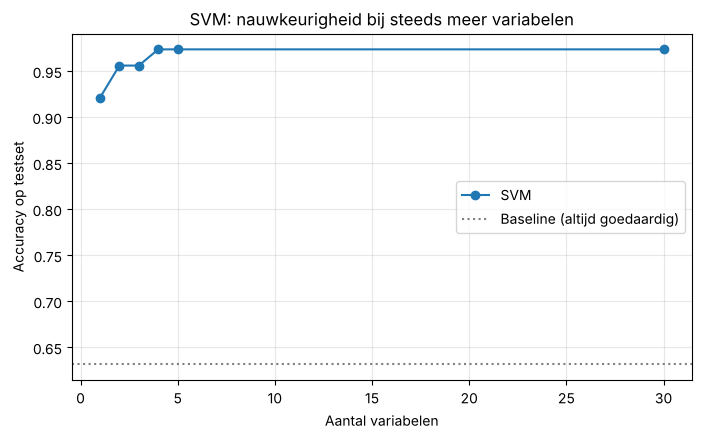

In [27]:
### Doel: Stapsgewijs variabelen toevoegen en na elke stap de nauwkeurigheid tonen
### In: Xb_train_s, Xb_test_s, yb_train, yb_test
### Uit: tabel + plot met de test-accuracy per aantal variabelen
# Volgorde op basis van de dataverkenning: we beginnen met de sterkste variabele en voegen daarna steeds een variabele
# toe die iets anders meet (grootte, textuur, gladheid, vorm). Radius, perimeter en area zijn bijna hetzelfde,
# dus van die groep gebruiken we maar één variabele.
volgorde = ["concave points_worst",   # sterkste correlatie met de diagnose
            "perimeter_worst",        # grootte van de celkern
            "texture_worst",          # textuur (weinig samenhang met grootte, dus nieuwe informatie)
            "smoothness_worst",       # gladheid van de rand
            "concavity_mean"]         # hoe diep de inkepingen in de rand zijn

rijen = []
for k in [1, 2, 3, 4, 5]:
    acc, _ = evalueer_svm(volgorde[:k])
    rijen.append({"aantal variabelen": k, "laatst toegevoegd": volgorde[k - 1], "test-accuracy": round(acc, 4)})

# Ter vergelijking: alle 30 variabelen
acc_alle, _ = evalueer_svm(Xb_train_s.columns.tolist())
rijen.append({"aantal variabelen": 30, "laatst toegevoegd": "(alle variabelen)", "test-accuracy": round(acc_alle, 4)})
forward_tabel = pd.DataFrame(rijen)
print(forward_tabel.to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(forward_tabel["aantal variabelen"], forward_tabel["test-accuracy"], marker="o", label="SVM")
plt.axhline(basis, color="gray", linestyle=":", label="Baseline (altijd goedaardig)")
plt.xlabel("Aantal variabelen"); plt.ylabel("Accuracy op testset"); plt.title("SVM: nauwkeurigheid bij steeds meer variabelen")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Resultaat van het toevoegen van variabelen:** de nauwkeurigheid stijgt snel bij de eerste variabelen en vlakt daarna af. Met 1 variabele halen we 92.1%, met 2 variabelen 95.6%, met 3 variabelen 95.6% en met 4 en 5 variabelen 97.4%. Het model met **alle 30 variabelen** scoort 97.4%, dus niet beter dan het model met 5 variabelen: veel variabelen zijn redundant (zie de multicollineariteit) en voegen weinig toe. Let op: de testset heeft maar 114 patiënten, dus één patiënt scheelt al ongeveer 0,9 procentpunt. Kleine verschillen tussen stappen zijn dus niet echt betekenisvol.

Variabelen in het uiteindelijke model: ['concave points_worst', 'perimeter_worst', 'texture_worst', 'smoothness_worst', 'concavity_mean']

Accuracy testset: 0.9737

                 precision    recall  f1-score   support

 goedaardig (B)       0.96      1.00      0.98        72
kwaadaardig (M)       1.00      0.93      0.96        42

       accuracy                           0.97       114
      macro avg       0.98      0.96      0.97       114
   weighted avg       0.97      0.97      0.97       114



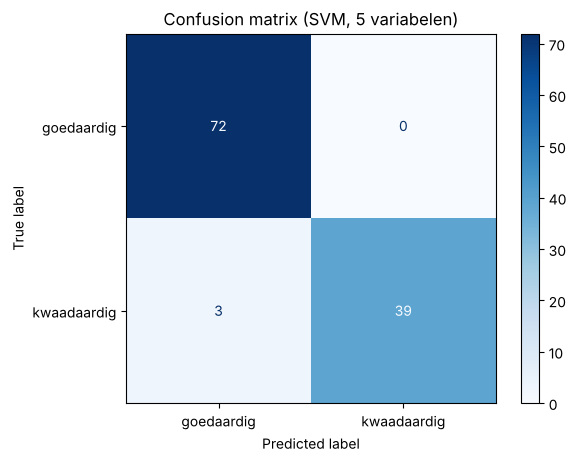

Cross-validatie accuracy (5 variabelen): 0.9692 (per stuk: [0.978 0.989 0.956 0.967 0.956])
Cross-validatie accuracy (alle 30 variabelen): 0.9758


In [28]:
### Doel: Het uiteindelijke model evalueren: confusion matrix, precision/recall en een korte cross-validatie
### In: volgorde, Xb_train_s, Xb_test_s, yb_train, yb_test
### Uit: confusion matrix, classification report en cross-validatie-score voor het gekozen aantal variabelen
from sklearn.model_selection import cross_val_score

k_final = 5
final_feats = volgorde[:k_final]
print("Variabelen in het uiteindelijke model:", final_feats)
acc_f, model_f = evalueer_svm(final_feats)
pred_f = model_f.predict(Xb_test_s[final_feats])
print(f"\nAccuracy testset: {acc_f:.4f}\n")
print(classification_report(yb_test, pred_f, target_names=["goedaardig (B)", "kwaadaardig (M)"]))
ConfusionMatrixDisplay.from_predictions(yb_test, pred_f, display_labels=["goedaardig", "kwaadaardig"], cmap="Blues")
plt.title(f"Confusion matrix (SVM, {k_final} variabelen)"); plt.show()

# Cross-validatie: de trainingsdata wordt in 5 stukken gesplitst; elk stuk is een keer de 'test'. Dit laat zien of het resultaat stabiel is.
cv_f = cross_val_score(SVC(kernel="rbf", C=1.0, gamma="scale"), Xb_train_s[final_feats], yb_train, cv=5)
cv_alle = cross_val_score(SVC(kernel="rbf", C=1.0, gamma="scale"), Xb_train_s, yb_train, cv=5)
print(f"Cross-validatie accuracy ({k_final} variabelen): {cv_f.mean():.4f} (per stuk: {cv_f.round(3)})")
print(f"Cross-validatie accuracy (alle 30 variabelen): {cv_alle.mean():.4f}")

Wanneer ben je klaar?

**Wanneer ben je klaar?** We stoppen bij **5 variabelen** (`concave points_worst`, `perimeter_worst`, `texture_worst`, `smoothness_worst`, `concavity_mean`). Redenen: (1) de nauwkeurigheid stijgt van 1 naar 4 variabelen en blijft daarna gelijk, (2) met 5 variabelen halen we dezelfde score als met alle 30 variabelen, en (3) een kleiner model is eenvoudiger en sneller. Het uiteindelijke model heeft een **accuracy van 97.4% op de testset** (111 van de 114 patiënten correct). De cross-validatie (5-voudig, op de trainingsdata) geeft gemiddeld 96.9% voor 5 variabelen en 97.6% voor alle 30 variabelen, dus het resultaat is stabiel en beide modellen zijn ongeveer even goed. In de confusion matrix zien we 0 goedaardige tumor(en) die onterecht als kwaadaardig zijn aangemerkt (vals alarm) en 3 kwaadaardige tumor(en) die we gemist hebben (recall voor kwaadaardig: 92.9%, precision: 100.0%). In de praktijk is een gemiste kwaadaardige tumor veel erger dan een vals alarm. Hyperparameter tuning van `C` en `gamma` is nog niet gedaan en past bij de volgende opdracht.